In [1]:
import pandas as pd
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import gzip

In [15]:
table = pd.read_csv('../data/processed/combined_matrix.tsv', sep='\t', index_col='Name' )
table.columns = table.columns.str.replace("_quant", "", regex=False)
table = table.round().astype(int)
Meta = pd.DataFrame({
    'sample': ['ERR458493', 'ERR458494', 'ERR458495', 'ERR458500', 'ERR458501', 'ERR458502'],
    'group': ['Normal','Normal','Normal','Mutated','Mutated','Mutated'],
})
Meta = Meta.set_index("sample")
table_t= table.transpose()
print(all(table_t.index == Meta.index))
#print(table_t.head())
#print(Meta.head())

True


In [3]:
dds = DeseqDataSet(
    counts = table_t,
    metadata = Meta,
    design = "~group",
    refit_cooks= True
)

dds.deseq2()

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 1.39 seconds.

Fitting dispersion trend curve...
/home/fb214/miniconda3/envs/BIOTECNIKA_INTERNSHIP/lib/python3.10/site-packages/pydeseq2/dds.py:807: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.17 seconds.

Fitting MAP dispersions...
... done in 2.11 seconds.

Fitting LFCs...
... done in 1.05 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



In [4]:
stat_res = DeseqStats(dds, contrast=['group', 'Mutated', 'Normal'] )
stat_res.summary()

result_df= stat_res.results_df
result_df= result_df.dropna(subset=['padj'])


clean_results =result_df[(result_df['padj']<0.05) & (result_df['log2FoldChange'].abs()>1)]
sorted_results= clean_results.sort_values('padj')
sorted_results.head(20)


Running Wald tests...


Log2 fold change & Wald test p-value: group Mutated vs Normal
                baseMean  log2FoldChange     lfcSE      stat        pvalue  \
Name                                                                         
YPL071C_mRNA   39.559517        0.649043  0.295709  2.194875  2.817256e-02   
YLL050C_mRNA  578.809615        0.577687  0.105685  5.466108  4.600239e-08   
YMR172W_mRNA   71.850891        0.192083  0.238894  0.804051  4.213672e-01   
YOR185C_mRNA   81.620258       -0.293688  0.213020 -1.378688  1.679910e-01   
YLL032C_mRNA   28.898214       -0.342721  0.378826 -0.904694  3.656277e-01   
...                  ...             ...       ...       ...           ...   
YPL276W         1.563760        2.303041  1.906473  1.208012  2.270428e-01   
YIL175W        11.223256       -0.177842  0.463183 -0.383955  7.010115e-01   
YLL016W        47.847130        0.744534  0.293813  2.534042  1.127552e-02   
YLL017W         8.203138        0.440768  0.534246  0.825029  4.093552e-01   
YI

... done in 0.63 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Name,,,,,,
YDR077W_mRNA,4128.929521,-3.796422,0.088879,-42.714442,0.000000e+00,0.000000e+00
YDR342C_mRNA,3159.526478,-3.359636,0.087182,-38.535837,0.000000e+00,0.000000e+00
YHR174W_mRNA,21124.679443,-1.506359,0.044374,-33.946658,1.366438e-252,2.823972e-249
YAL038W_mRNA,8030.868722,-1.714002,0.058700,-29.199329,1.977603e-187,3.065285e-184
YFR015C_mRNA,924.735809,-3.260506,0.117041,-27.857707,8.688046e-171,1.077318e-167
YDR033W_mRNA,487.498070,-3.574025,0.136862,-26.114037,2.525810e-150,2.610003e-147
YHR092C_mRNA,1326.242581,-2.448959,0.094047,-26.039662,1.761739e-149,1.560398e-146
YML123C_mRNA,846.639296,-5.010463,0.193492,-25.894913,7.598912e-148,5.889156e-145
YLR058C_mRNA,756.028630,-3.127757,0.123477,-25.330784,1.463477e-141,1.008173e-138


In [5]:
result_df.loc[result_df.index.str.contains("YOR290C")]
table.loc[["YOR290C_mRNA"]]


,ERR458493,ERR458494,ERR458495,ERR458500,ERR458501,ERR458502
Name,,,,,,
YOR290C_mRNA,143,138,125,0,0,0


In [6]:
log_counts = np.log2(table_t +1 )
scaled = StandardScaler().fit_transform(log_counts)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled)

print(pca_result)
print(pca.explained_variance_ratio_)

[[-72.28575754 -34.33043272]
 [-73.57109421  17.73449351]
 [-75.0714132   16.13924751]
 [ 74.04824514   0.97941348]
 [ 73.79367759   0.59497717]
 [ 73.08634221  -1.11769894]]
[0.84079772 0.04537097]


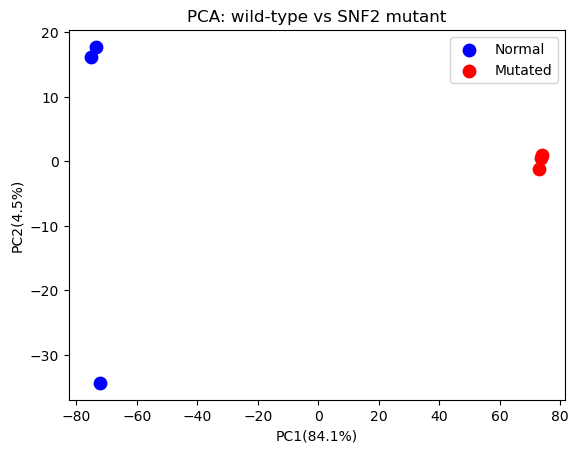

In [ ]:
pca_dif = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=table_t.index)
pca_dif['group']= Meta['group']

for group, color in [('Normal', 'blue'), ('Mutated', 'red')]:
    subset= pca_dif[pca_dif['group'] ==group]
    plt.scatter(subset['PC1'], subset['PC2'], color= color, label= group, s=80)

plt.xlabel(f"PC1({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA: wild-type vs SNF2 mutant")
plt.legend()
plt.savefig("../results/pca_plot.png", dpi=300)
plt.close()

In [14]:
row =[]

with gzip.open('../data/raw/Saccharomyces_cerevisiae.R64-1-1.cdna.all.fa.gz','rt') as f:
    for line in f:
        if not line.startswith('>'):
            continue

        line= line.strip()[1:]
        transcript_id = line.split(" ")[0]

        symbol= ""
        if 'gene_symbol' in line:
            symbol = line.split('gene_symbol:')[1].split(" ")[0]

        description = ""
        if 'description' in line:
            description= line.split('description:')[1]

        row.append({
            'transcript_id': transcript_id,
            'symbol': symbol,
            'description': description
        })

annot =pd.DataFrame(row).set_index('transcript_id')
annot.shape
#annot.head()


(6612, 2)

In [9]:
clean_results.shape
clean_results.head()
print("Up in mutant:  ", (clean_results["log2FoldChange"] > 0).sum())
print("Down in mutant:", (clean_results["log2FoldChange"] < 0).sum())

annotated =sorted_results.join(annot, how='left')
print(annotated['description'].isna().sum())
pd.set_option('display.max_colwidth', 300)
annotated[['log2FoldChange','padj', 'symbol', 'description']]

Up in mutant:   169
Down in mutant: 285
0


,log2FoldChange,padj,symbol,description
Name,,,,
YDR077W_mRNA,-3.796422,0.000000e+00,SED1,"Major stress-induced structural GPI-cell wall glycoprotein; associates with translating ribosomes, possible role in mitochondrial genome maintenance; ORF contains two distinct variable minisatellites; SED1 has a paralog, SPI1, that arose from the whole genome duplication [Source:SGD;Acc:S000002484]"
YDR342C_mRNA,-3.359636,0.000000e+00,HXT7,"High-affinity glucose transporter; member of the major facilitator superfamily, nearly identical to Hxt6p, expressed at high basal levels relative to other HXTs, expression repressed by high glucose levels; HXT7 has a paralog, HXT4, that arose from the whole genome duplication [Source:SGD;Acc:S0..."
YHR174W_mRNA,-1.506359,2.823972e-249,ENO2,"Enolase II, a phosphopyruvate hydratase; catalyzes conversion of 2-phosphoglycerate to phosphoenolpyruvate during glycolysis and the reverse reaction during gluconeogenesis; expression induced in response to glucose; ENO2 has a paralog, ENO1, that arose from the whole genome duplication [Source:..."
YAL038W_mRNA,-1.714002,3.065285e-184,CDC19,"Pyruvate kinase; functions as a homotetramer in glycolysis to convert phosphoenolpyruvate to pyruvate, the input for aerobic (TCA cycle) or anaerobic (glucose fermentation) respiration; regulated via allosteric activation by fructose bisphosphate; CDC19 has a paralog, PYK2, that arose from the w..."
YFR015C_mRNA,-3.260506,1.077318e-167,GSY1,"Glycogen synthase; expression induced by glucose limitation, nitrogen starvation, environmental stress, and entry into stationary phase; GSY1 has a paralog, GSY2, that arose from the whole genome duplication; relocalizes from nucleus to cytoplasmic foci upon DNA replication stress [Source:SGD;Ac..."
...,...,...,...,...
YFR010W-A_mRNA,2.019316,4.629391e-02,,"Dubious open reading frame; unlikely to encode a functional protein, based on available experimental and comparative sequence data; completely overlaps the uncharacterized gene YFR011C; identified by expression profiling and mass spectrometry [Source:SGD;Acc:S000028824]"
YDL085W_mRNA,1.144334,4.681654e-02,NDE2,"Mitochondrial external NADH dehydrogenase; catalyzes the oxidation of cytosolic NADH; Nde1p and Nde2p are involved in providing the cytosolic NADH to the mitochondrial respiratory chain; NDE2 has a paralog, NDE1, that arose from the whole genome duplication [Source:SGD;Acc:S000002243]"
YJR094C_mRNA,1.377590,4.704530e-02,IME1,Master regulator of meiosis that is active only during meiotic events; activates transcription of early meiotic genes through interaction with Ume6p; degraded by the 26S proteasome following phosphorylation by Ime2p; transcription is negatively regulated in cis by the IRT1 long noncoding antisen...


In [10]:
annotated[annotated['log2FoldChange'] > 0][['symbol', 'description', 'log2FoldChange', 'padj']].head(15)


,symbol,description,log2FoldChange,padj
Name,,,,
YER081W_mRNA,SER3,"3-phosphoglycerate dehydrogenase and alpha-ketoglutarate reductase; 3PG dehydrogenase that catalyzes the first step in serine and glycine biosynthesis; also functions as an alpha-ketoglutarate reductase, converting alpha-ketoglutarate to D-2-hydroxyglutarate (D-2HG); localizes to the cytoplasm; ...",2.961047,2.065145e-74
YEL071W_mRNA,DLD3,"2-hydroxyglutarate transhydrogenase, and minor D-lactate dehydrogenase; converts D-2-hydroxyglutarate (D-2HG), an oncometabolite, to alpha-ketoglutarate in the presence of FAD, with concomitant reduction of pyruvate to D-lactate; minor lactate dehydrogenase activity; component of the retrograde ...",1.203941,1.549067e-22
YDR524W-C_mRNA,,Putative protein of unknown function; small ORF identified by SAGE; deletion strains are moderately sensitive to the radiomimetic drug bleomycin [Source:SGD;Acc:S000028740],1.725804,6.711236e-20
YCR005C_mRNA,CIT2,"Citrate synthase, peroxisomal isozyme involved in glyoxylate cycle; catalyzes condensation of acetyl coenzyme A and oxaloacetate to form citrate; expression is controlled by Rtg1p and Rtg2p transcription factors; SCF-Ucc1 regulates level of Cit2p to maintain citrate homeostasis; oxaloacetate-dep...",2.117201,4.333873e-17
YLR108C_mRNA,,"Protein of unknown function; green fluorescent protein (GFP)-fusion protein localizes to the nucleus; YLR108C is not an esssential gene; protein abundance increases in response to DNA replication stress; YLR108C has a paralog, YDR132C, that arose from the whole genome duplication [Source:SGD;Acc...",2.090086,2.196649e-14
YMR056C_mRNA,AAC1,Mitochondrial inner membrane ADP/ATP translocator; exchanges cytosolic ADP for mitochondrially synthesized ATP; phosphorylated; Aac1p is a minor isoform while Pet9p is the major ADP/ATP translocator; relocalizes from mitochondrion to cytoplasm upon DNA replication stress [Source:SGD;Acc:S000004660],1.866058,6.082205e-12
YKR039W_mRNA,GAP1,General amino acid permease; Gap1p senses the presence of amino acid substrates to regulate localization to the plasma membrane when needed; essential for invasive growth [Source:SGD;Acc:S000001747],1.309370,2.430027e-11
YDR111C_mRNA,ALT2,"Catalytically inactive alanine transaminase; expression is repressed in the presence of alanine and repression is mediated by Nrg1p; ALT2 has a paralog, ALT1, that arose from the whole genome duplication [Source:SGD;Acc:S000002518]",1.294878,2.269710e-10
YOR348C_mRNA,PUT4,Proline permease; required for high-affinity transport of proline; also transports the toxic proline analog azetidine-2-carboxylate (AzC); PUT4 transcription is repressed in ammonia-grown cells [Source:SGD;Acc:S000005875],2.386226,2.616948e-09


In [11]:
plot_df=result_df.copy()
plot_df['neg_log10_padj']= -np.log10(plot_df['padj'].replace(0, 1e-300))

def local_gene(row):

    if row['padj']<.05 and row['log2FoldChange']> 1:
        return "Up in Mutant"
    elif row['padj']<.05 and row['log2FoldChange']<-1:
        return "Down in Mutant"
    else:
        return "Not Significant"

plot_df['Category']= plot_df.apply(local_gene, axis=1)
print(plot_df['Category'].value_counts())

Category
Not Significant    5746
Down in Mutant      285
Up in Mutant        169
Name: count, dtype: int64


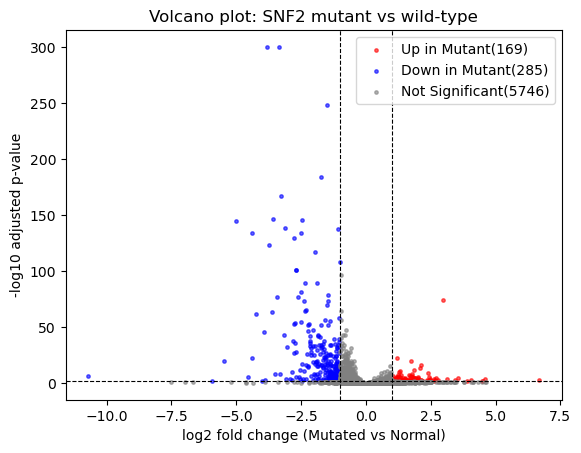

In [ ]:
colors= {"Up in Mutant":"red", "Down in Mutant":'blue', "Not Significant":'grey'}

for category, color in colors.items():
    subset= plot_df[plot_df['Category']==category]
    plt.scatter(subset['log2FoldChange'],subset['neg_log10_padj'], color=color, s=6, alpha= 0.6, label=f"{category}({len(subset)})")

plt.axhline(-np.log10(0.05), color="black", linestyle="--", linewidth=0.8)
plt.axvline(1, color="black", linestyle="--", linewidth=0.8)
plt.axvline(-1, color="black", linestyle="--", linewidth=0.8)

plt.xlabel('log2 fold change (Mutated vs Normal)')
plt.ylabel('-log10 adjusted p-value')
plt.title("Volcano plot: SNF2 mutant vs wild-type")
plt.legend()
plt.savefig("../results/volcano_plot.png", dpi=300)
plt.show()


In [13]:
result_df.to_csv("../results/dge_all_genes.csv")
annotated.to_csv("../results/dge_significant_genes_annotated.csv")
print("Saved")

Saved
